In [4]:
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

In [2]:
file = "data/raw/5.tif"
with Image.open(file) as img:
    arr = np.array(img)

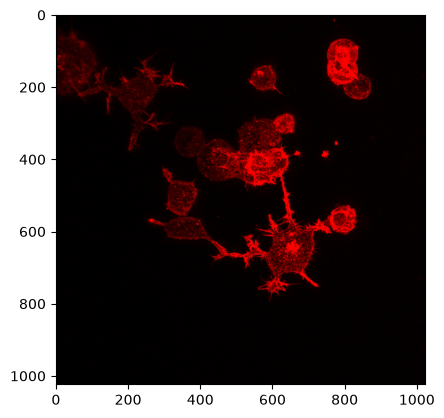

In [3]:
plt.imshow(arr, cmap='gray')

In [4]:
np.shape(arr)

(1024, 1024, 3)

In [5]:
from dataset import get_datasets, get_image_paths
train_ds, val_ds, n_train, n_val = get_datasets()

I0000 00:00:1792416435.298688    6715 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1792416440.537797    6715 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6


In [6]:
print(f"Train images    : {n_train}  |  Val images: {n_val}")

Train images    : 5  |  Val images: 1


In [7]:
total_images = sum(1 for _ in val_ds)
print(f"Total images: {total_images}")

Total images: 1


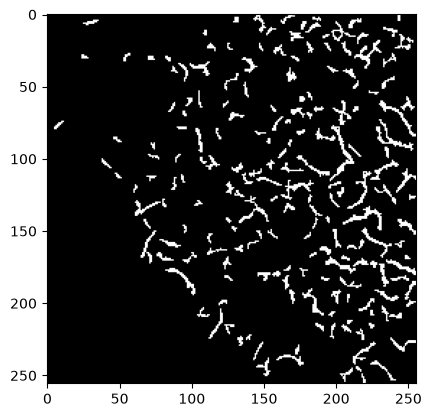

In [11]:
for images, lable in val_ds.take(1):
    lable = np.array(lable)

plt.imshow(lable[0, :, :, 0], cmap='gray')

In [24]:
paths = get_image_paths("data/raw")
paths

['data/raw/1.tif',
 'data/raw/2.tif',
 'data/raw/3.tif',
 'data/raw/4.tif',
 'data/raw/5.tif',
 'data/raw/6.tif']

In [2]:
import os, numpy as np, cv2, tensorflow as tf
import matplotlib.pyplot as plt
import config, dataset

# ---- settings ----
IMAGE_DIR = "data/raw"
IMAGE_NAME = None      # e.g. "4.tif"; None = use first image
N_AUG = 8
SEED = 42
OUT = "aug_samples"
os.makedirs(OUT, exist_ok=True)
tf.random.set_seed(SEED)

def u8(a): return (np.clip(np.squeeze(np.asarray(a)), 0, 1) * 255).astype(np.uint8)

def overlay(img, mask, alpha=0.6):
    rgb = np.stack([img]*3, -1).astype(np.float32)
    m = (mask > 127)[..., None]
    return np.where(m, (1-alpha)*rgb + alpha*np.array([0,255,0], np.float32), rgb).astype(np.uint8)

# ---- load + label one image (same as training pipeline) ----
paths = dataset.get_image_paths(IMAGE_DIR)
path = next(p for p in paths if os.path.basename(p) == IMAGE_NAME) if IMAGE_NAME else paths[0]
print("Using:", path)

img = cv2.resize(dataset.load_tif_image(path), config.IMAGE_SIZE, interpolation=cv2.INTER_LINEAR)
mask = dataset.preprocess_image(img)["edge_mask"].astype(np.float32)
img_t = tf.convert_to_tensor(img[..., None], tf.float32)
mask_t = tf.convert_to_tensor(mask[..., None], tf.float32)

# ---- original + augmented ----
imgs, ovls, titles = [u8(img_t)], [overlay(u8(img_t), u8(mask_t))], ["Original"]
for i in range(1, N_AUG + 1):
    a_i, a_m = dataset._tf_augment(img_t, mask_t)
    a_i, a_m = u8(a_i.numpy()), u8(a_m.numpy())
    imgs.append(a_i); ovls.append(overlay(a_i, a_m)); titles.append(f"Augmented {i}")
    cv2.imwrite(f"{OUT}/aug_{i:02d}_image.png", a_i)
    cv2.imwrite(f"{OUT}/aug_{i:02d}_mask.png", a_m)
    cv2.imwrite(f"{OUT}/aug_{i:02d}_overlay.png", cv2.cvtColor(ovls[-1], cv2.COLOR_RGB2BGR))

# ---- 3x3 grids ----
def grid(panels, name, cmap=None):
    fig, axs = plt.subplots(3, 3, figsize=(12, 12))
    for ax, p, t in zip(axs.ravel(), panels, titles):
        ax.imshow(p, cmap=cmap); ax.set_title(t); ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT}/{name}", dpi=200, bbox_inches="tight"); plt.show()

grid(imgs, "grid_images.png", cmap="gray")
grid(ovls, "grid_overlays.png")
print("Saved to", os.path.abspath(OUT))

Using: data/raw/1.tif


I0000 00:00:1793179209.143324    9304 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 3050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.6
/tmp/ipykernel_9304/84283791.py:46: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.savefig(f"{OUT}/{name}", dpi=200, bbox_inches="tight"); plt.show()


Saved to /home/harsh/CV_work/group_8/aug_samples


In [1]:
from dataset import _load_and_label_numpy

I0000 00:00:1793439557.331398  220073 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


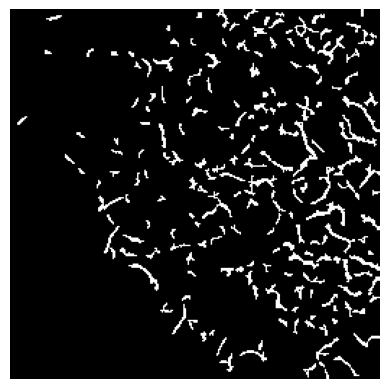

In [18]:
from dataset import _load_and_label_numpy
import tensorflow as tf
file = "data/raw/1.tif"

imgarr, labelarr = _load_and_label_numpy(tf.constant(file))

plt.imshow(labelarr.squeeze(), cmap='gray')
plt.axis('off')
plt.savefig("label1.png", bbox_inches='tight', pad_inches=0)
plt.show()